# Classifying variable roles from graph paths

The precision matrix gives the linear association between two variables after conditioning on all other selected variables:

$$
\rho_{ij\cdot -ij}=-\frac{\Omega_{ij}}{\sqrt{\Omega_{ii}\Omega_{jj}}},\qquad \Omega=\Sigma^{-1}.
$$

Here, $\Sigma$ is the covariance matrix of the selected variables, $\Omega$ is its inverse, $i$ and $j$ identify two variables, $-ij$ denotes all remaining selected variables, and $\rho_{ij\cdot -ij}$ is their full-order partial correlation.

,Field,Value
0,Provider,Kenneth R. French Data Library
1,Archive,49 Industry Portfolios daily archive
2,Return type,Daily value-weighted return
3,Analysis start,2019-01-02
4,Analysis end,2025-12-31
5,Complete dates,1760
6,Selected industries,8
7,Selection rule,Eight named industries fixed before the calcul...


,First industry,Second industry,Pairwise correlation,Full-order partial correlation,Absolute change
0,Banks,Finance,0.907867,0.643378,0.264489
1,Real estate,Finance,0.804775,0.184397,0.620378
2,Banks,Real estate,0.792393,0.222084,0.570309
3,Banks,Insurance,0.752894,0.226431,0.526463
4,Insurance,Finance,0.740571,0.077924,0.662647
5,Finance,Software,0.723952,0.444748,0.279204
6,Banks,Oil,0.686455,0.287696,0.398758
7,Insurance,Utilities,0.674684,0.371924,0.30276
8,Insurance,Real estate,0.641374,-0.002247,0.643621
9,Finance,Utilities,0.640994,0.133366,0.507629


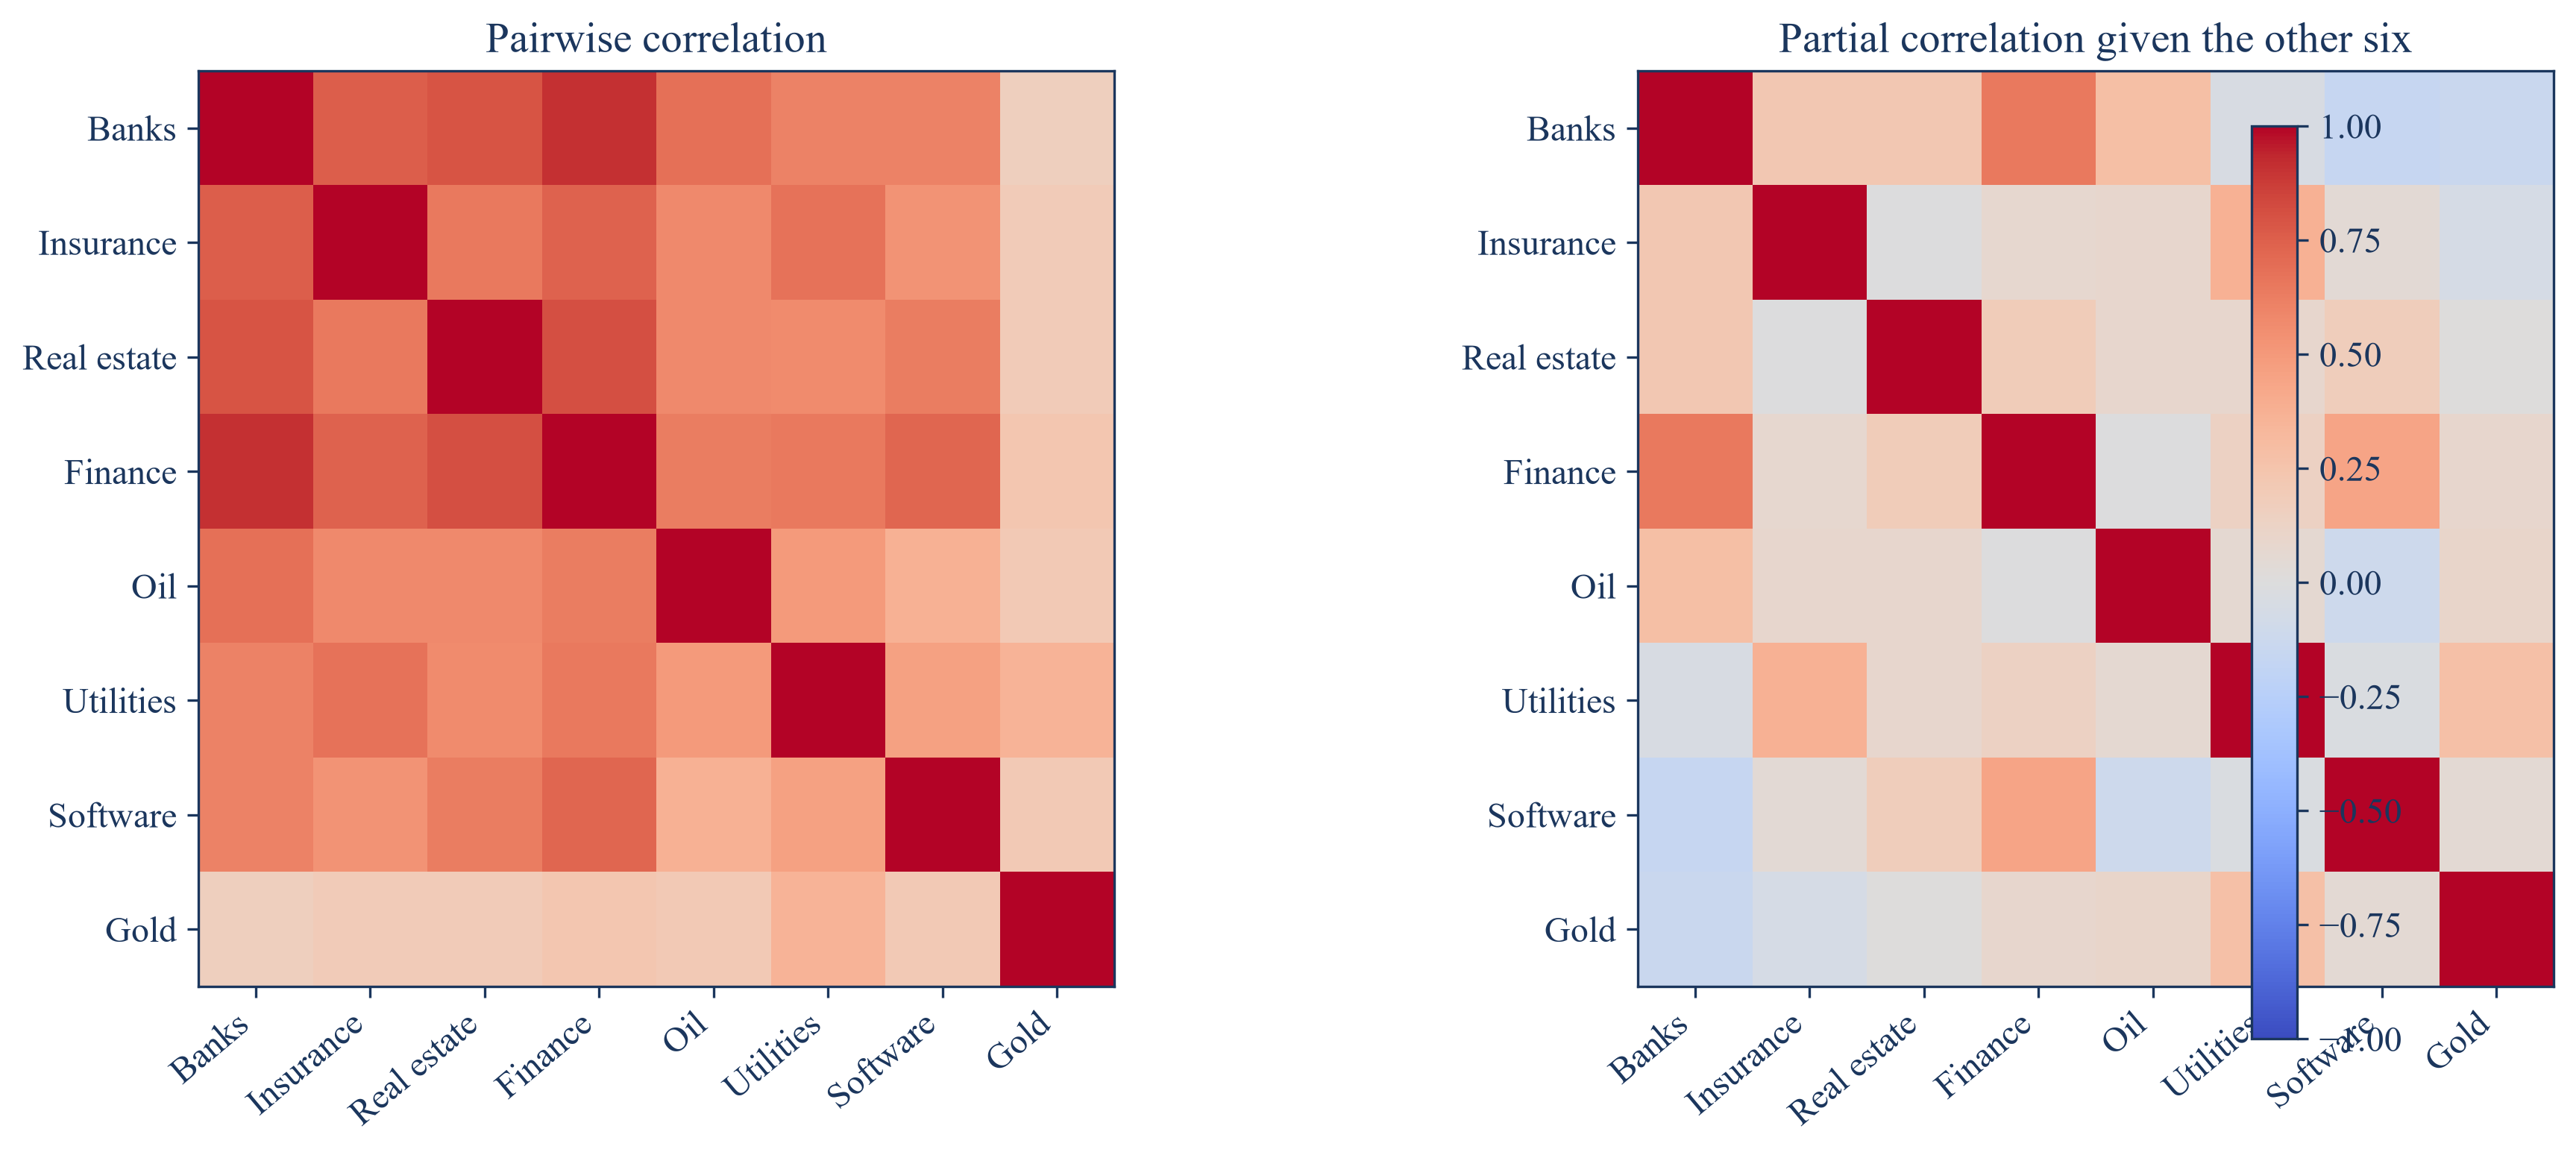

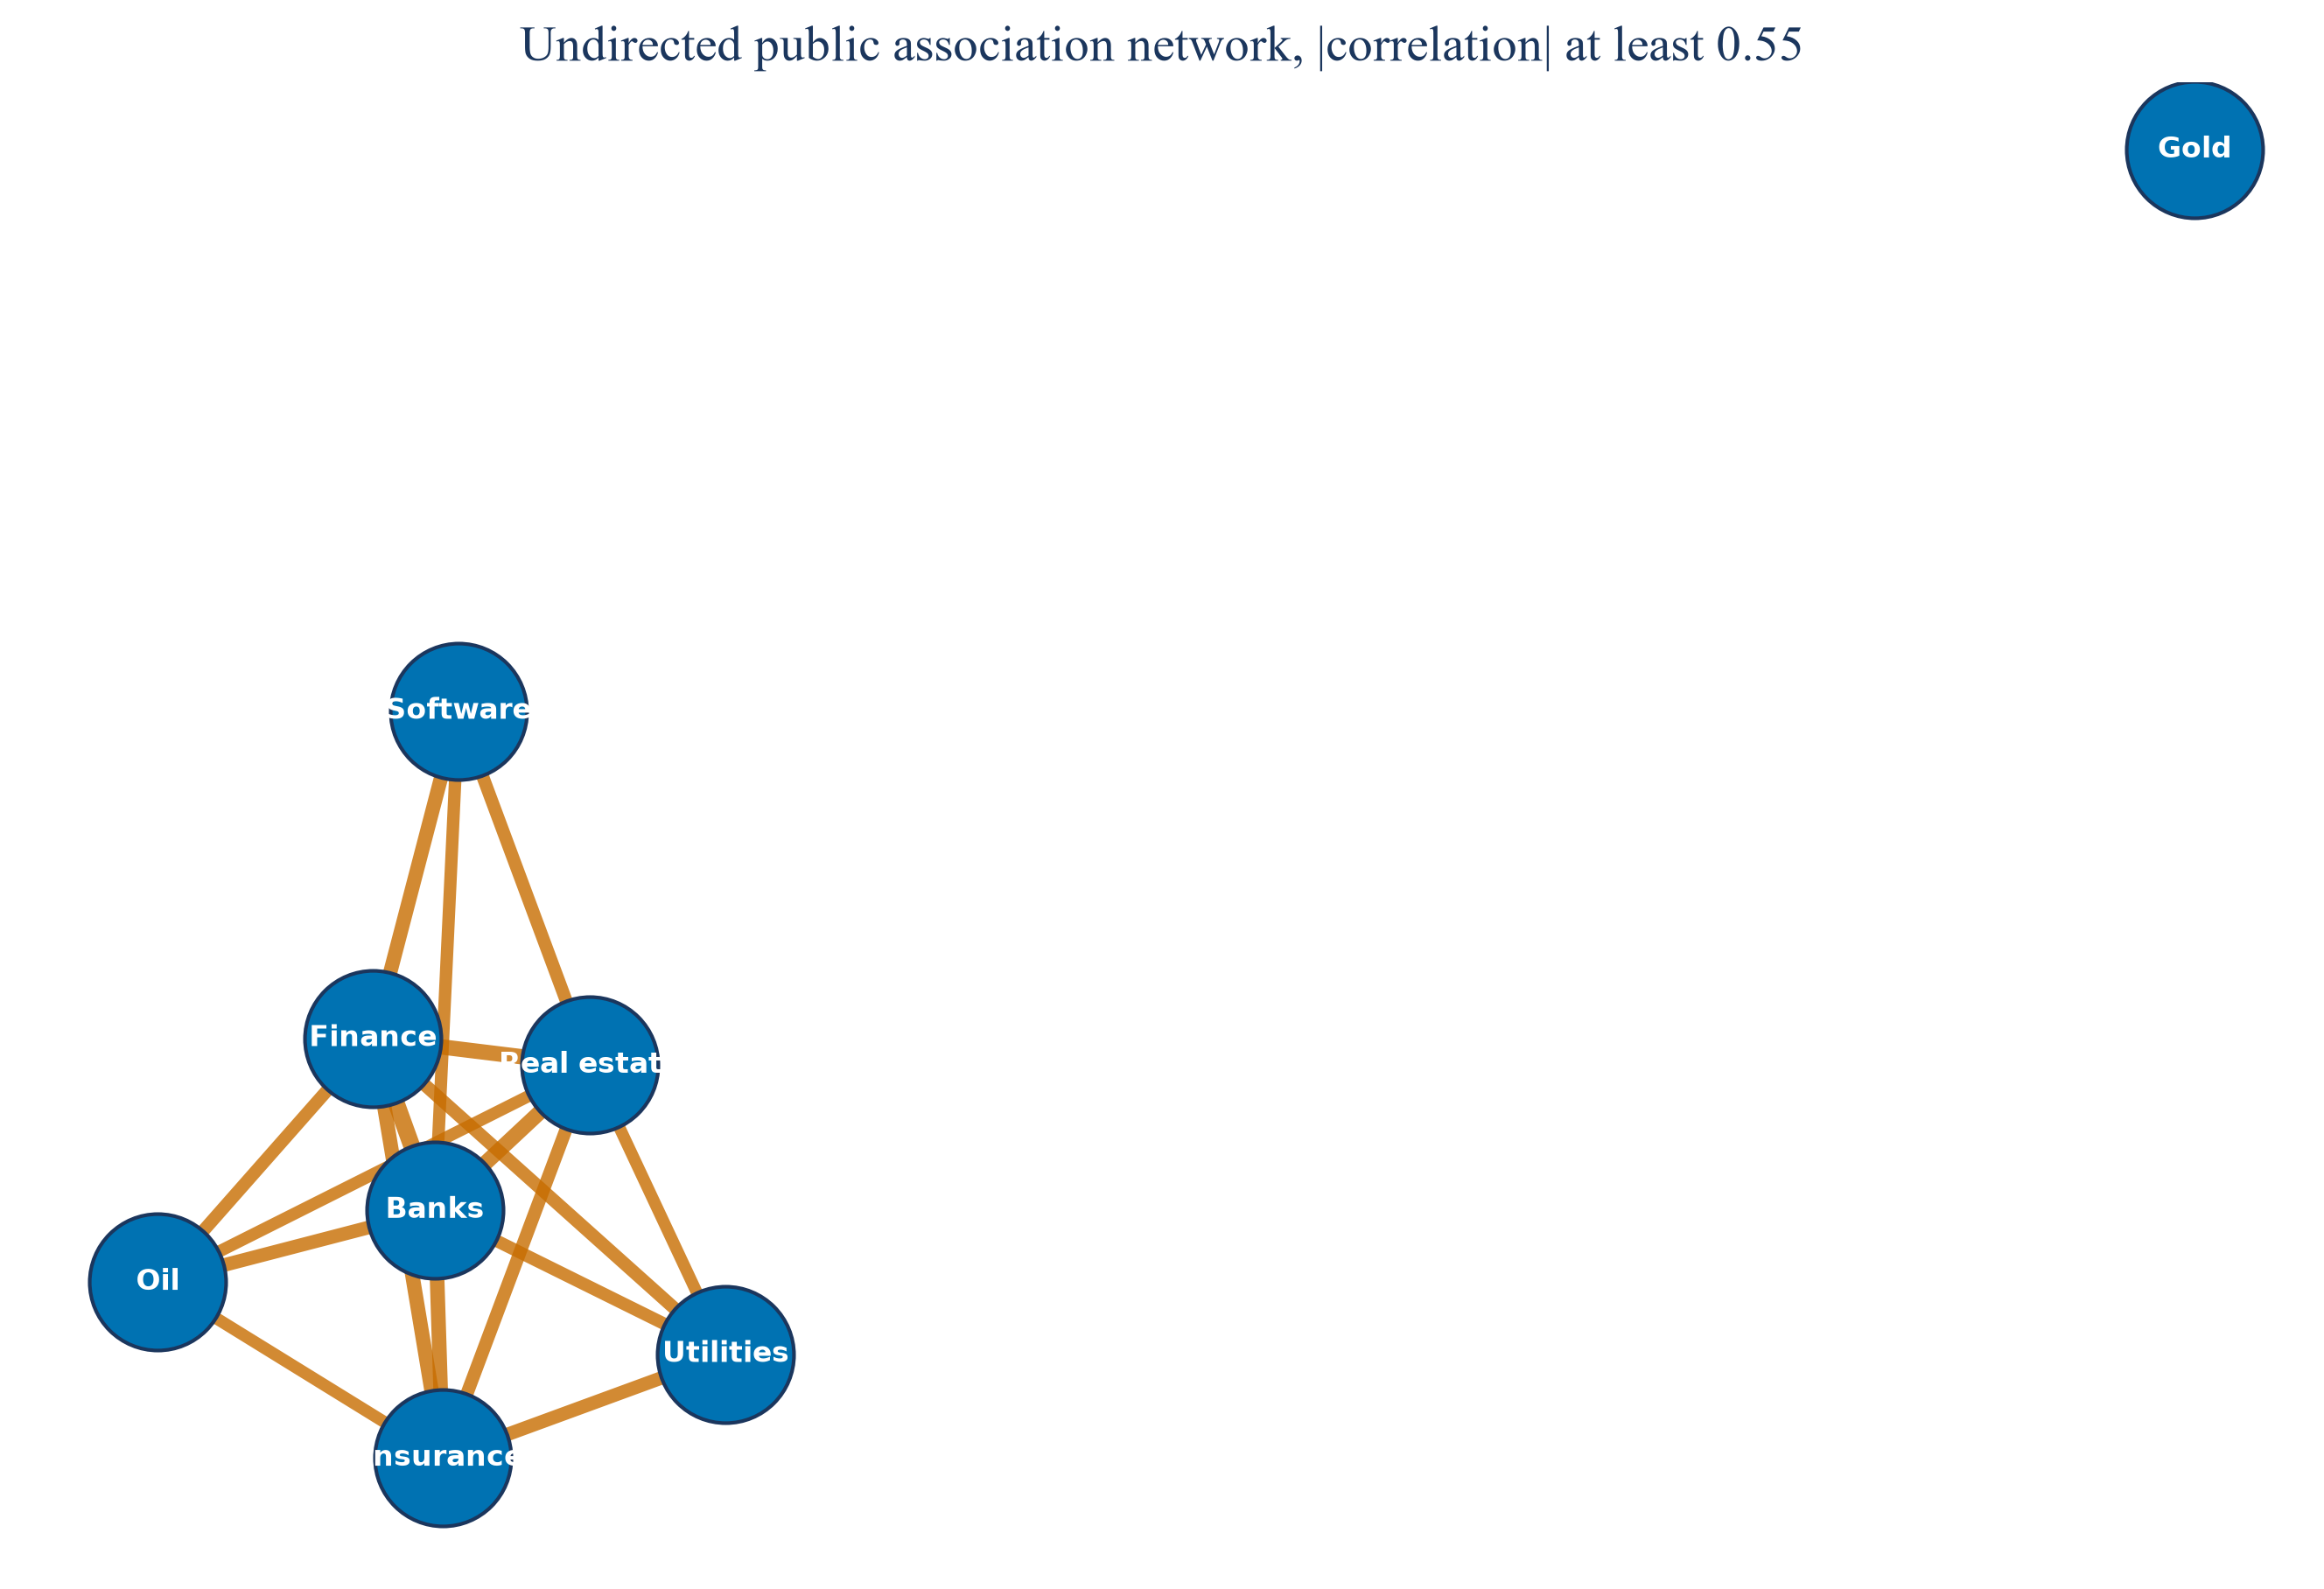

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset

FIGURES = ROOT / "outputs" / "figures" / "01_causal_roles"
TABLES = ROOT / "outputs" / "tables" / "01_causal_roles"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def draw_directed_graph(axis, graph, positions, title, colors=None, labels=None, edge_styles=None, node_size=1250, font_size=9):
    node_colors = [palette["cyan"] if colors is None else colors.get(node, palette["cyan"]) for node in graph.nodes]
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=node_colors, node_size=node_size, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, labels=labels, font_color=palette["background"], font_weight="bold", font_size=font_size)
    if edge_styles is None:
        nx.draw_networkx_edges(graph, positions, ax=axis, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    else:
        for edge in graph.edges:
            style = edge_styles.get(edge, "solid")
            nx.draw_networkx_edges(graph, positions, ax=axis, edgelist=[edge], edge_color=palette["text"], width=1.8, style=style, arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    axis.set_title(title)
    axis.set_axis_off()

def partial_correlation(x, y, controls=None):
    x_values = np.asarray(x, dtype=float).reshape(-1)
    y_values = np.asarray(y, dtype=float).reshape(-1)
    if controls is None or np.asarray(controls).size == 0:
        return float(np.corrcoef(x_values, y_values)[0, 1])
    control_values = np.asarray(controls, dtype=float)
    if control_values.ndim == 1:
        control_values = control_values.reshape(-1, 1)
    design = np.column_stack([np.ones(len(control_values)), control_values])
    x_residual = x_values - design @ np.linalg.lstsq(design, x_values, rcond=None)[0]
    y_residual = y_values - design @ np.linalg.lstsq(design, y_values, rcond=None)[0]
    return float(np.corrcoef(x_residual, y_residual)[0, 1])

def regression_summary(frame, outcome, treatment, controls):
    columns = [treatment] + list(controls)
    design = np.column_stack([np.ones(len(frame)), frame[columns].to_numpy(dtype=float)])
    response = frame[outcome].to_numpy(dtype=float)
    coefficients = np.linalg.lstsq(design, response, rcond=None)[0]
    fitted = design @ coefficients
    residual = response - fitted
    total = response - response.mean()
    r_squared = 1.0 - float(residual @ residual) / float(total @ total)
    return float(coefficients[1]), r_squared

def path_is_active(graph, path, conditioned):
    conditioned_set = set(conditioned)
    collider_openers = set(conditioned_set)
    for node in conditioned_set:
        collider_openers.update(nx.ancestors(graph, node))
    for index in range(1, len(path) - 1):
        previous_node = path[index - 1]
        middle_node = path[index]
        next_node = path[index + 1]
        collider = graph.has_edge(previous_node, middle_node) and graph.has_edge(next_node, middle_node)
        if collider and middle_node not in collider_openers:
            return False
        if not collider and middle_node in conditioned_set:
            return False
    return True

def path_records(graph, source, target, conditioned):
    records = []
    paths = list(nx.all_simple_paths(graph.to_undirected(), source=source, target=target))
    for path in paths:
        colliders = []
        for index in range(1, len(path) - 1):
            previous_node = path[index - 1]
            middle_node = path[index]
            next_node = path[index + 1]
            if graph.has_edge(previous_node, middle_node) and graph.has_edge(next_node, middle_node):
                colliders.append(middle_node)
        records.append({"Path": " - ".join(path), "Conditioning set": ", ".join(sorted(conditioned)) if conditioned else "None", "Collider nodes": ", ".join(colliders) if colliders else "None", "Active": path_is_active(graph, path, conditioned)})
    return records

def fit_sem_covariance(covariance, graph, nodes):
    covariance_values = np.asarray(covariance, dtype=float)
    node_index = {node: index for index, node in enumerate(nodes)}
    coefficients = np.zeros_like(covariance_values)
    residual_variances = np.zeros(len(nodes), dtype=float)
    for node in nodes:
        row = node_index[node]
        parents = list(graph.predecessors(node))
        if parents:
            parent_indices = [node_index[parent] for parent in parents]
            beta = covariance_values[row, parent_indices] @ np.linalg.inv(covariance_values[np.ix_(parent_indices, parent_indices)])
            coefficients[row, parent_indices] = beta
            residual_variances[row] = covariance_values[row, row] - beta @ covariance_values[parent_indices, row]
        else:
            residual_variances[row] = covariance_values[row, row]
    transform = np.linalg.inv(np.eye(len(nodes)) - coefficients)
    implied = transform @ np.diag(residual_variances) @ transform.T
    return coefficients, residual_variances, implied

def role_color(role):
    mapping = {"confounder": palette["amber"], "mediator": palette["green"], "collider": palette["rose"], "instrument": palette["violet"], "ancestor_of_outcome": palette["cyan"], "descendant_of_outcome": palette["muted"], "descendant_of_treatment": palette["muted"], "independent": palette["grid"]}
    return mapping.get(role, palette["cyan"])

import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

sys.path.insert(0, str(ROOT))
from causal_notebook_tools import classify_causal_role, is_collider, is_confounder, is_instrument, is_mediator

selected_columns = ["Banks", "Insur", "RlEst", "Fin", "Oil", "Util", "Softw", "Gold"]
display_names = {"Banks": "Banks", "Insur": "Insurance", "RlEst": "Real estate", "Fin": "Finance", "Oil": "Oil", "Util": "Utilities", "Softw": "Software", "Gold": "Gold"}
public_sample = industry_returns[selected_columns].rename(columns=display_names).copy()
public_provenance = pd.DataFrame({"Field": ["Provider", "Archive", "Return type", "Analysis start", "Analysis end", "Complete dates", "Selected industries", "Selection rule"], "Value": ["Kenneth R. French Data Library", "49 Industry Portfolios daily archive", "Daily value-weighted return", str(public_sample.index.min().date()), str(public_sample.index.max().date()), len(public_sample), len(public_sample.columns), "Eight named industries fixed before the calculation"]})
public_correlation = public_sample.corr()
public_covariance = public_sample.cov()
precision = np.linalg.inv(public_covariance.to_numpy(dtype=float))
scaling = np.sqrt(np.outer(np.diag(precision), np.diag(precision)))
partial_values = -precision / scaling
np.fill_diagonal(partial_values, 1.0)
public_partial_correlation = pd.DataFrame(partial_values, index=public_sample.columns, columns=public_sample.columns)
association_rows = []
for left_index, left in enumerate(public_sample.columns):
    for right in public_sample.columns[left_index + 1:]:
        association_rows.append({"First industry": left, "Second industry": right, "Pairwise correlation": public_correlation.loc[left, right], "Full-order partial correlation": public_partial_correlation.loc[left, right], "Absolute pairwise correlation": abs(public_correlation.loc[left, right]), "Absolute change": abs(public_partial_correlation.loc[left, right] - public_correlation.loc[left, right])})
public_association_summary = pd.DataFrame(association_rows).sort_values("Absolute pairwise correlation", ascending=False).reset_index(drop=True)
public_pairwise_partial_comparison = public_association_summary.head(12).drop(columns=["Absolute pairwise correlation"])
save_table(public_provenance, "causal_public_data_provenance", "Public observations used for the Chapter 23 association example.", "tab:chapter23-public-provenance")
save_table(public_association_summary, "public_association_summary", "Pairwise and full-order partial correlations for the selected public industries.", "tab:chapter23-public-associations")
save_table(public_pairwise_partial_comparison, "public_pairwise_partial_comparison", "Largest public pairwise correlations and their partial-correlation counterparts.", "tab:chapter23-pairwise-partial")
display(public_provenance)
display(public_pairwise_partial_comparison)

figure, axes = plt.subplots(1, 2, figsize=(13, 5.3))
first = axes[0].imshow(public_correlation.to_numpy(dtype=float), vmin=-1, vmax=1, cmap="coolwarm")
second = axes[1].imshow(public_partial_correlation.to_numpy(dtype=float), vmin=-1, vmax=1, cmap="coolwarm")
for axis, title in zip(axes, ["Pairwise correlation", "Partial correlation given the other six"]):
    axis.set_title(title)
    axis.set_xticks(range(len(public_sample.columns)), public_sample.columns, rotation=40, ha="right")
    axis.set_yticks(range(len(public_sample.columns)), public_sample.columns)
figure.colorbar(second, ax=axes, fraction=0.022, pad=0.02)
figure.tight_layout()
save_figure(figure, "public_correlation_partial_matrices")

threshold = 0.55
association_graph = nx.Graph()
association_graph.add_nodes_from(public_sample.columns)
for _, row in public_association_summary.iterrows():
    if row["Absolute pairwise correlation"] >= threshold:
        association_graph.add_edge(row["First industry"], row["Second industry"], weight=row["Absolute pairwise correlation"])
network_positions = nx.spring_layout(association_graph, seed=2303, weight="weight")
figure, axis = plt.subplots(figsize=(9, 6.2))
edge_widths = [1.0 + 4.0 * association_graph[source][target]["weight"] for source, target in association_graph.edges]
nx.draw_networkx_nodes(association_graph, network_positions, ax=axis, node_color=palette["cyan"], edgecolors=palette["text"], node_size=1400)
nx.draw_networkx_labels(association_graph, network_positions, ax=axis, font_color=palette["background"], font_weight="bold", font_size=8)
nx.draw_networkx_edges(association_graph, network_positions, ax=axis, edge_color=palette["amber"], width=edge_widths, alpha=0.8)
axis.set_title(f"Undirected public association network, |correlation| at least {threshold:.2f}")
axis.set_axis_off()
figure.tight_layout()
save_figure(figure, "public_association_network")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Why conditioning screens do not identify causal roles

The change caused by conditioning on one candidate variable is a descriptive association screen:

$$
\Delta_Z=\rho_{XY\cdot Z}-\rho_{XY}.
$$

Here, $X$ is the selected treatment candidate, $Y$ is the selected outcome candidate, $Z$ is one candidate conditioning variable, $\rho_{XY}$ is their pairwise correlation, $\rho_{XY\cdot Z}$ is their partial correlation given $Z$, and $\Delta_Z$ is the resulting change in association rather than a causal-role label.

,Candidate variable,Pairwise correlation,Correlation after conditioning,Change,Absolute change
0,Real estate,0.907867,0.746136,-0.16173,0.16173
1,Insurance,0.907867,0.792063,-0.115804,0.115804
2,Oil,0.907867,0.84279,-0.065077,0.065077
3,Utilities,0.907867,0.850611,-0.057256,0.057256
4,Software,0.907867,0.854494,-0.053372,0.053372
5,Gold,0.907867,0.906433,-0.001434,0.001434


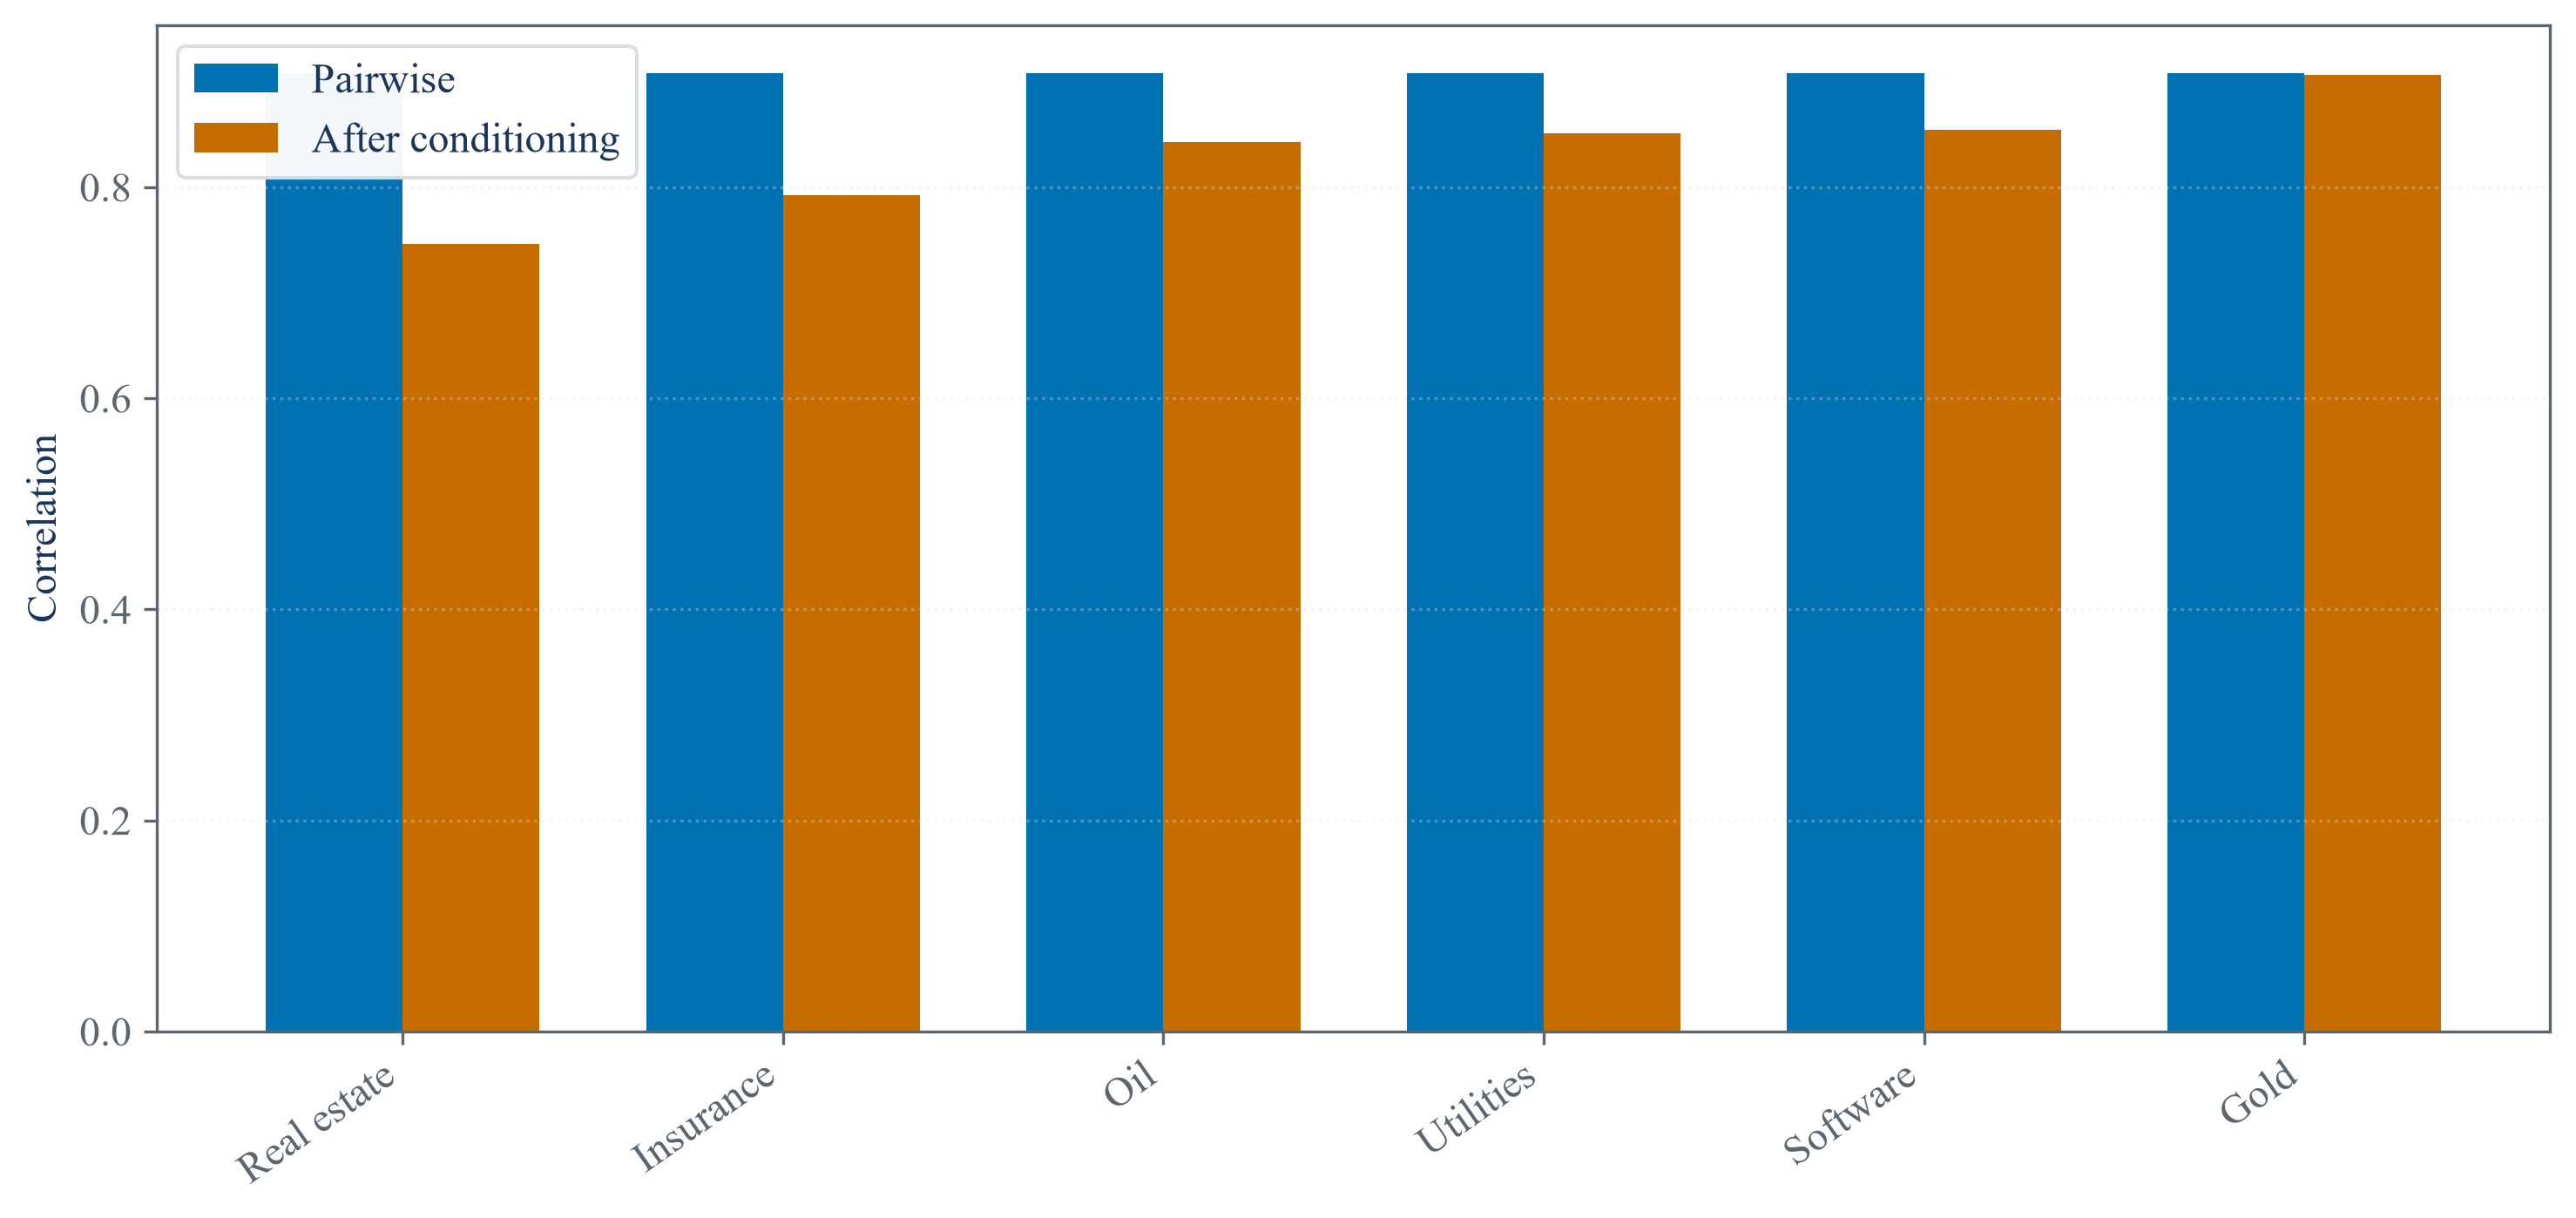

In [2]:
treatment_name = "Banks"
outcome_name = "Finance"
marginal_value = partial_correlation(public_sample[treatment_name], public_sample[outcome_name])
conditioning_rows = []
for candidate in [column for column in public_sample.columns if column not in {treatment_name, outcome_name}]:
    conditional_value = partial_correlation(public_sample[treatment_name], public_sample[outcome_name], public_sample[[candidate]])
    conditioning_rows.append({"Candidate variable": candidate, "Pairwise correlation": marginal_value, "Correlation after conditioning": conditional_value, "Change": conditional_value - marginal_value, "Absolute change": abs(conditional_value - marginal_value)})
public_conditioning_screen = pd.DataFrame(conditioning_rows).sort_values("Absolute change", ascending=False).reset_index(drop=True)
save_table(public_conditioning_screen, "public_conditioning_screen", "Association between banks and finance before and after one-variable conditioning.", "tab:chapter23-public-conditioning")
display(public_conditioning_screen)

figure, axis = plt.subplots(figsize=(10, 4.8))
positions = np.arange(len(public_conditioning_screen))
width = 0.36
axis.bar(positions - width / 2, public_conditioning_screen["Pairwise correlation"], width, label="Pairwise", color=palette["cyan"])
axis.bar(positions + width / 2, public_conditioning_screen["Correlation after conditioning"], width, label="After conditioning", color=palette["amber"])
axis.set_xticks(positions, public_conditioning_screen["Candidate variable"], rotation=35, ha="right")
axis.set_ylabel("Correlation")
axis.legend()
axis.grid(axis="y", alpha=0.35)
figure.tight_layout()
save_figure(figure, "public_conditioning_screen")

## Role Sets under Arrow Uncertainty

When several candidate graphs remain possible, a variable has a set of admissible roles rather than one established label:

$$
\mathcal R(Z;X,Y,\mathcal G)=\{r_G(Z;X,Y):G\in\mathcal G\}.
$$

Here, $\mathcal G$ is a set of candidate directed acyclic graphs, $G$ is one candidate, $X$ is the treatment candidate, $Y$ is the outcome candidate, $Z$ is the variable being classified, $r_G$ is the role assigned under $G$, and $\mathcal R$ is the resulting role set.

,Candidate graph,Insurance role,Directed edges,Acyclic
0,Insurance as confounder,confounder,3,True
1,Insurance as mediator,mediator,3,True
2,Insurance as collider,collider,3,True


,Candidate graph,Maximum covariance error,Smallest residual variance,Largest absolute coefficient
0,Insurance as confounder,0,0.000043,0.936172
1,Insurance as mediator,0,0.000043,0.746068
2,Insurance as collider,0,0.000045,0.837539


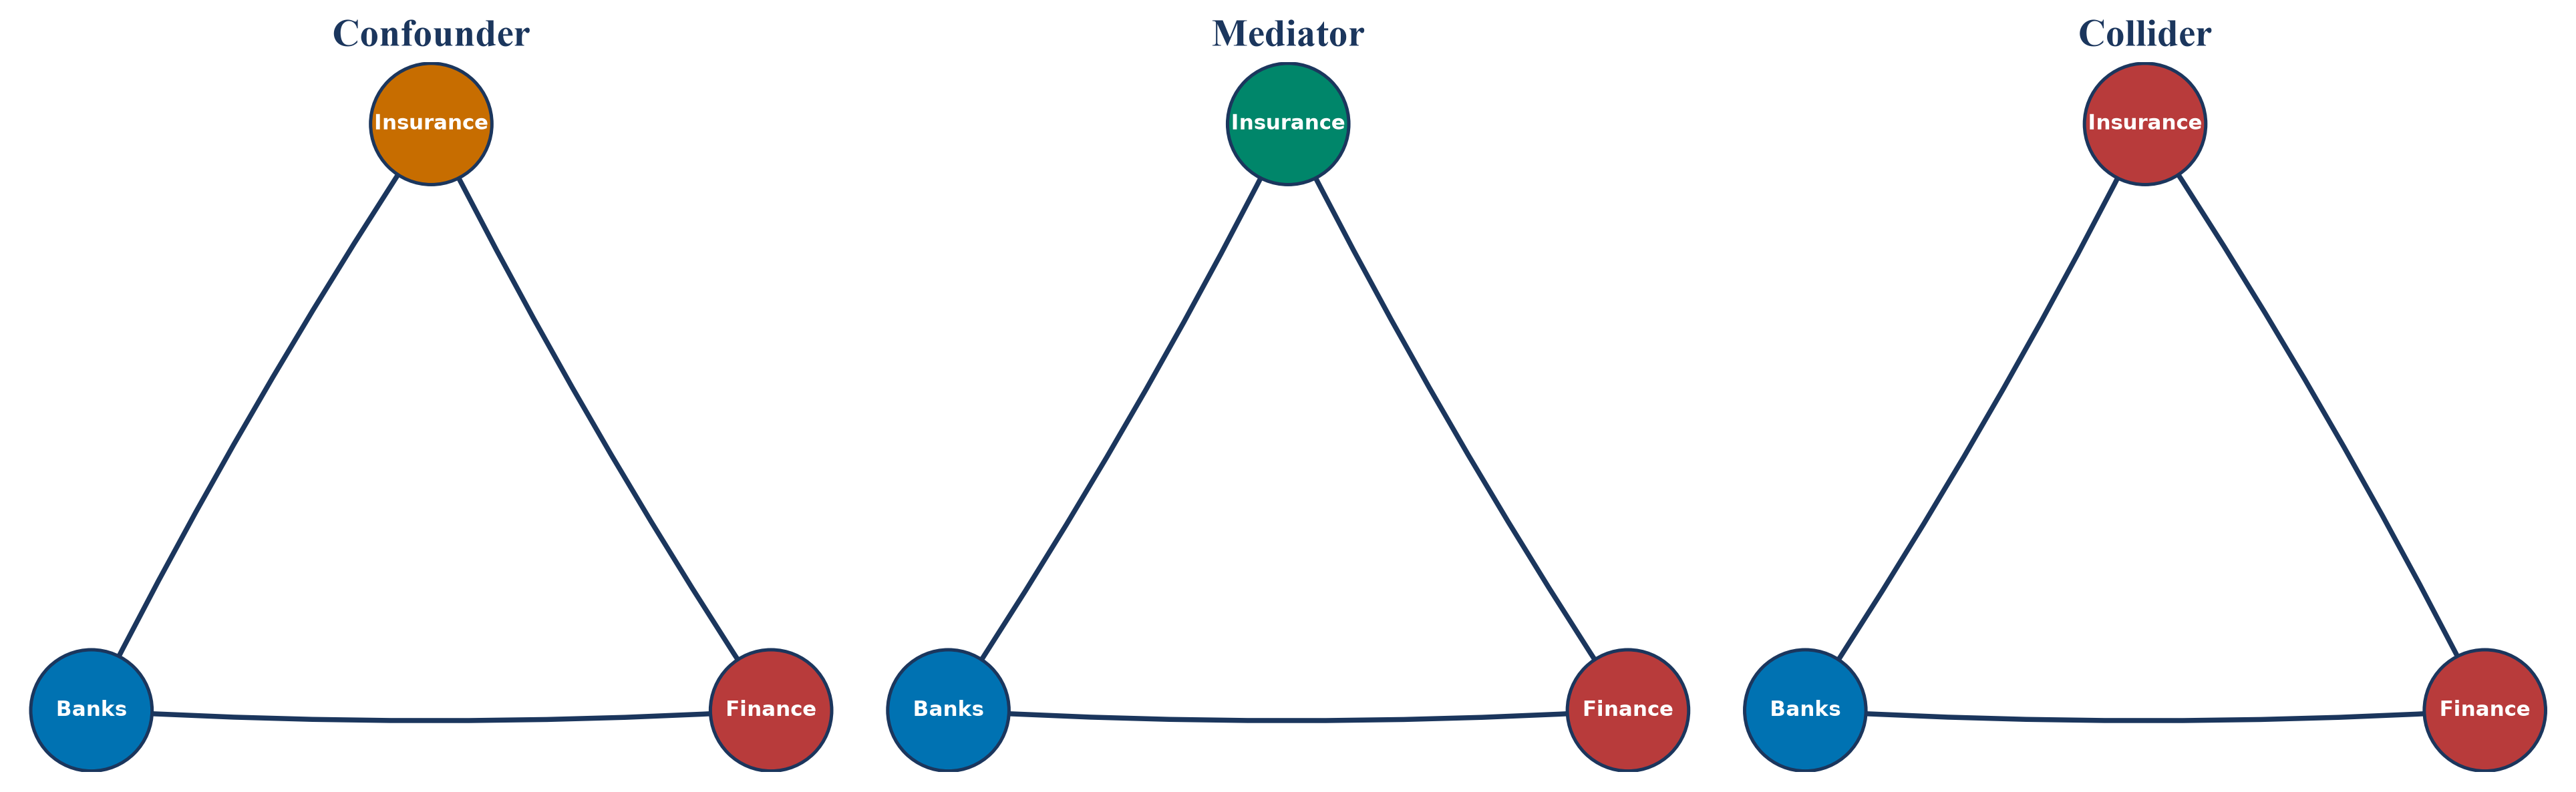

In [3]:
orientation_graphs = {
    "Insurance as confounder": nx.DiGraph([("Insurance", "Banks"), ("Insurance", "Finance"), ("Banks", "Finance")]),
    "Insurance as mediator": nx.DiGraph([("Banks", "Insurance"), ("Insurance", "Finance"), ("Banks", "Finance")]),
    "Insurance as collider": nx.DiGraph([("Banks", "Insurance"), ("Finance", "Insurance"), ("Banks", "Finance")]),
}
orientation_rows = []
triple_nodes = ["Banks", "Insurance", "Finance"]
triple_covariance = public_sample[triple_nodes].cov().to_numpy(dtype=float)
reconstruction_rows = []
for name, graph in orientation_graphs.items():
    role = classify_causal_role(graph, "Banks", "Finance", "Insurance")
    coefficients, residual_variances, implied = fit_sem_covariance(triple_covariance, graph, triple_nodes)
    orientation_rows.append({"Candidate graph": name, "Insurance role": role, "Directed edges": graph.number_of_edges(), "Acyclic": nx.is_directed_acyclic_graph(graph)})
    reconstruction_rows.append({"Candidate graph": name, "Maximum covariance error": float(np.max(np.abs(implied - triple_covariance))), "Smallest residual variance": float(residual_variances.min()), "Largest absolute coefficient": float(np.max(np.abs(coefficients)))})
orientation_role_uncertainty = pd.DataFrame(orientation_rows)
orientation_covariance_reconstruction = pd.DataFrame(reconstruction_rows)
save_table(orientation_role_uncertainty, "orientation_role_uncertainty", "Insurance roles under three candidate arrow orientations.", "tab:chapter23-orientation-roles")
save_table(orientation_covariance_reconstruction, "orientation_covariance_reconstruction", "Exact covariance representations under the three complete candidate graphs.", "tab:chapter23-orientation-reconstruction")
display(orientation_role_uncertainty)
display(orientation_covariance_reconstruction)

common_positions = {"Banks": (0, 0), "Insurance": (1, 1), "Finance": (2, 0)}
figure, axes = plt.subplots(1, 3, figsize=(13, 4.1))
for axis, (name, graph) in zip(axes, orientation_graphs.items()):
    role = classify_causal_role(graph, "Banks", "Finance", "Insurance")
    colors = {"Banks": palette["cyan"], "Finance": palette["rose"], "Insurance": role_color(role)}
    draw_directed_graph(axis, graph, common_positions, role.replace("_", " ").title(), colors, node_size=1900, font_size=7.5)
figure.tight_layout()
save_figure(figure, "public_orientation_alternatives")

## Covariance Reconstruction Does Not Choose the Arrows

A linear graph with coefficient matrix $B_G$ and diagonal disturbance covariance $D_G$ implies a covariance matrix through:

$$
\Sigma_G=(I-B_G)^{-1}D_G(I-B_G)^{-\mathsf T}.
$$

Here, $G$ is a candidate graph, $B_G$ contains its parent-to-child coefficients, $D_G$ contains disturbance variances, $I$ is the identity matrix, $-\mathsf T$ denotes inverse transpose, and $\Sigma_G$ is the covariance implied by that candidate graph.

,Pair,Windows,Mean,Standard deviation,Minimum,Maximum,First,Last
0,Banks-Finance,1635,0.889771,0.043615,0.76371,0.9814,0.929842,0.803378
1,Banks-Insurance,1635,0.654047,0.158617,0.254159,0.946665,0.598141,0.620784
2,Finance-Insurance,1635,0.634483,0.197085,0.184653,0.95306,0.640855,0.475403


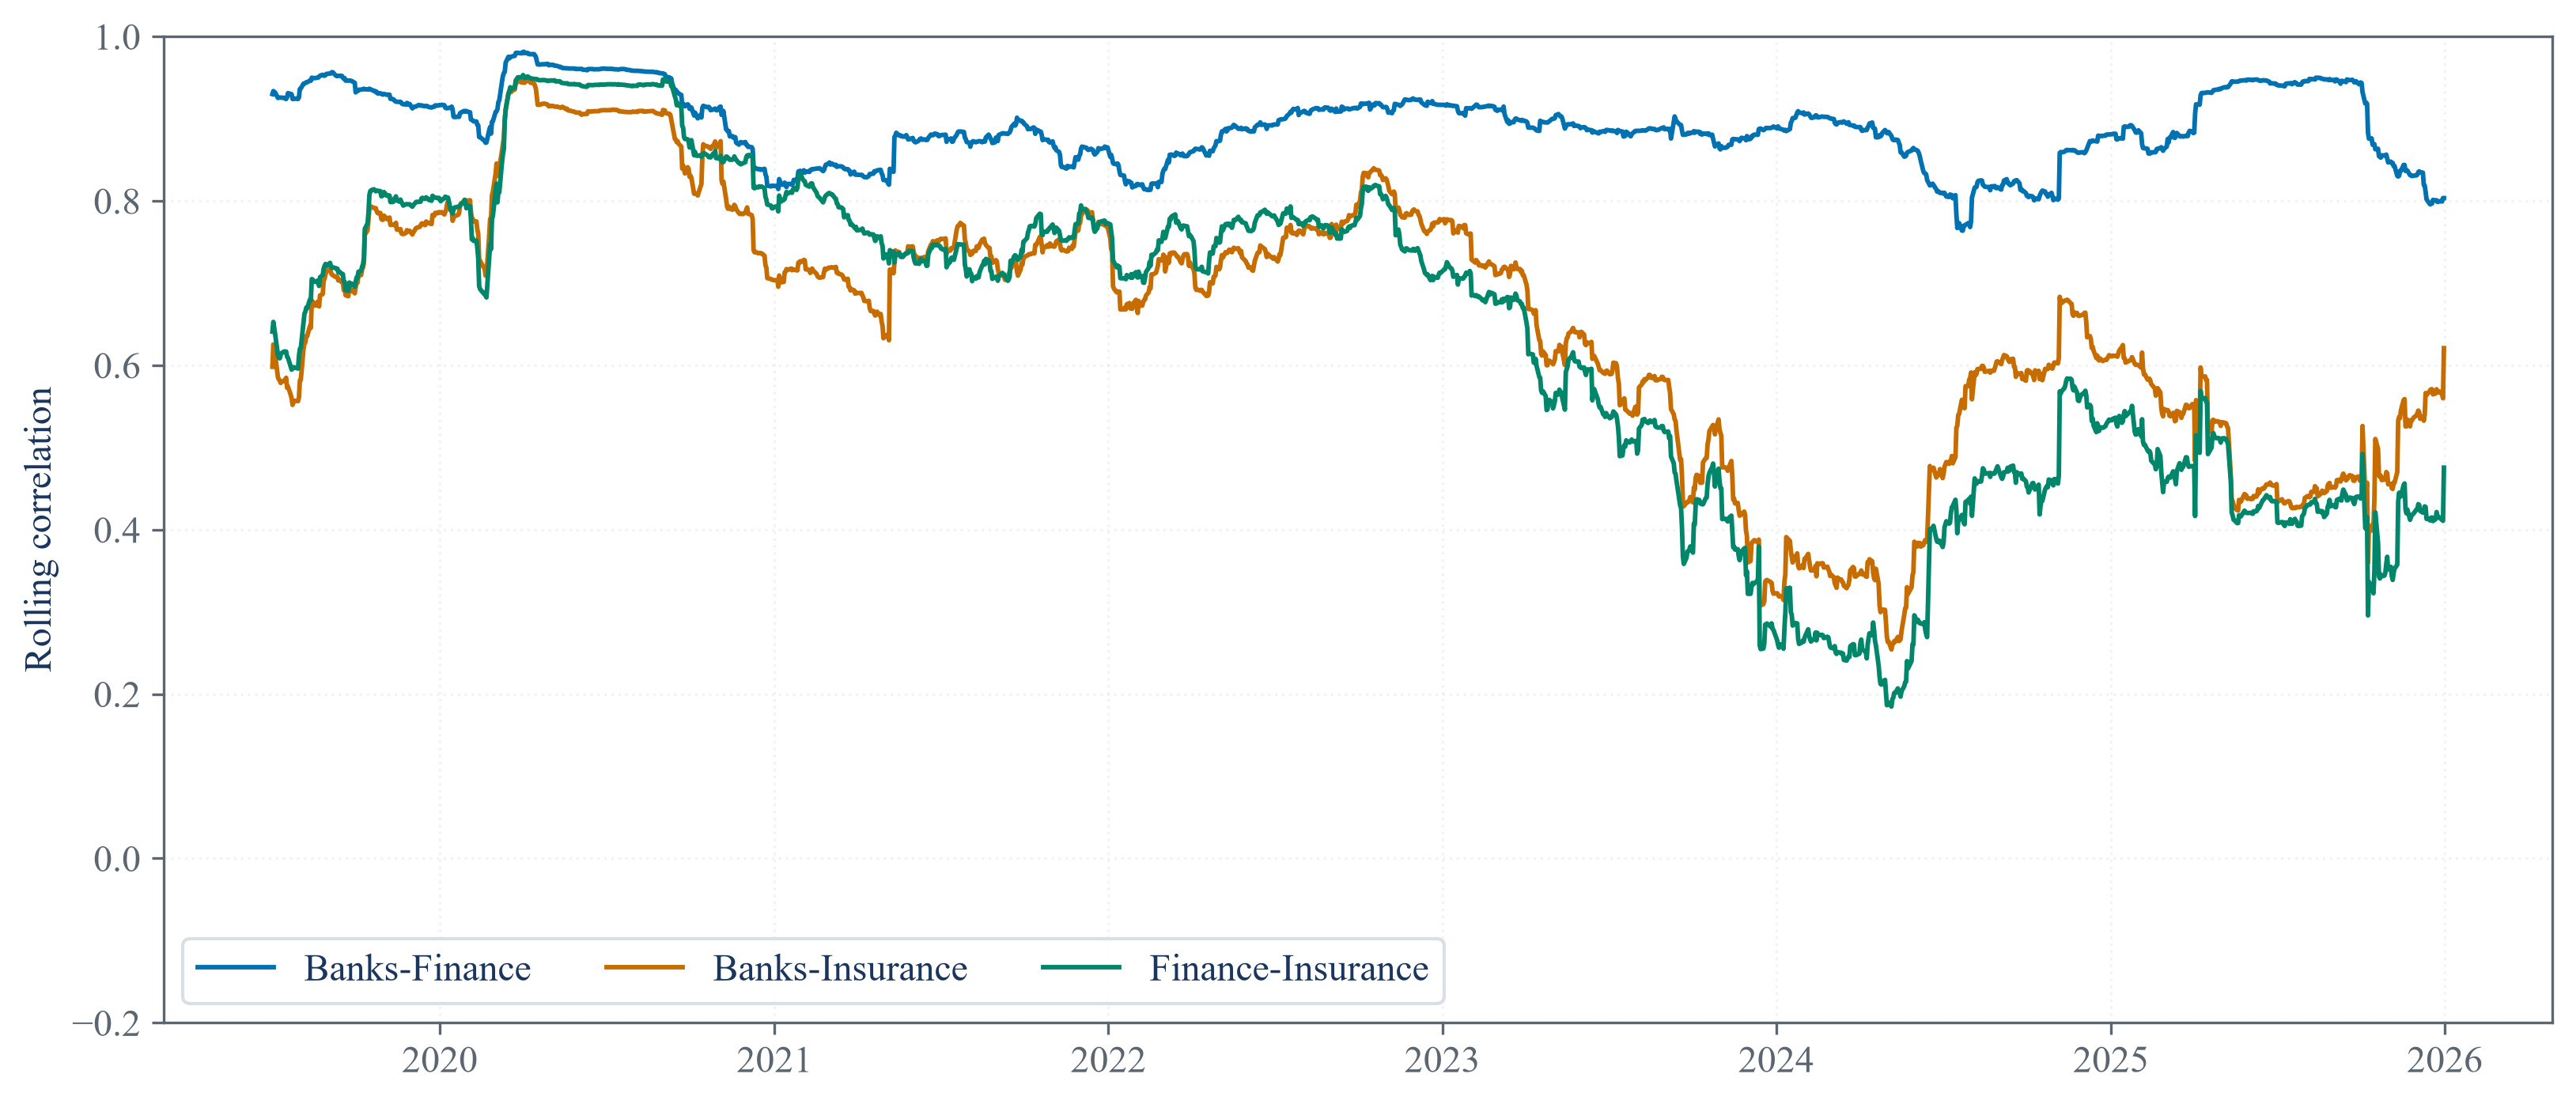

In [4]:
rolling_window = 126
rolling_correlations = public_sample[["Banks", "Insurance", "Finance"]].rolling(rolling_window).corr()
rolling_rows = []
for date in public_sample.index[rolling_window - 1:]:
    matrix = rolling_correlations.loc[date]
    rolling_rows.append({"Date": date, "Banks-Finance": matrix.loc["Banks", "Finance"], "Banks-Insurance": matrix.loc["Banks", "Insurance"], "Finance-Insurance": matrix.loc["Finance", "Insurance"]})
rolling_association = pd.DataFrame(rolling_rows).set_index("Date")
rolling_summary_rows = []
for pair in rolling_association.columns:
    series = rolling_association[pair].dropna()
    rolling_summary_rows.append({"Pair": pair, "Windows": len(series), "Mean": series.mean(), "Standard deviation": series.std(), "Minimum": series.min(), "Maximum": series.max(), "First": series.iloc[0], "Last": series.iloc[-1]})
rolling_association_summary = pd.DataFrame(rolling_summary_rows)
save_table(rolling_association_summary, "rolling_association_summary", "Rolling 126-day correlations among banks, insurance, and finance.", "tab:chapter23-rolling-association")
display(rolling_association_summary)

figure, axis = plt.subplots(figsize=(11, 4.8))
colors = [palette["cyan"], palette["amber"], palette["green"]]
for pair, color in zip(rolling_association.columns, colors):
    axis.plot(rolling_association.index, rolling_association[pair], label=pair, color=color, linewidth=1.4)
axis.set_ylabel("Rolling correlation")
axis.set_ylim(-0.2, 1.0)
axis.legend(ncol=3)
axis.grid(alpha=0.35)
figure.tight_layout()
save_figure(figure, "rolling_public_associations")

## Preserving Unresolved Edges

A graph summary should separate confidently directed edges from edges whose direction remains unresolved:

$$
E=E_{\rightarrow}\cup E_{?},\qquad E_{\rightarrow}\cap E_{?}=\varnothing.
$$

Here, $E$ is the reported edge set, $E_{\rightarrow}$ contains confidently directed edges, $E_{?}$ contains undirected, bidirected, or circle-marked edges, and the empty intersection prevents an unresolved edge from being silently treated as certain.

,From,To,Status
0,A,B,Directed


,First node,Second node,Status
0,A,D,bidirected
1,B,C,undirected
2,C,D,circle


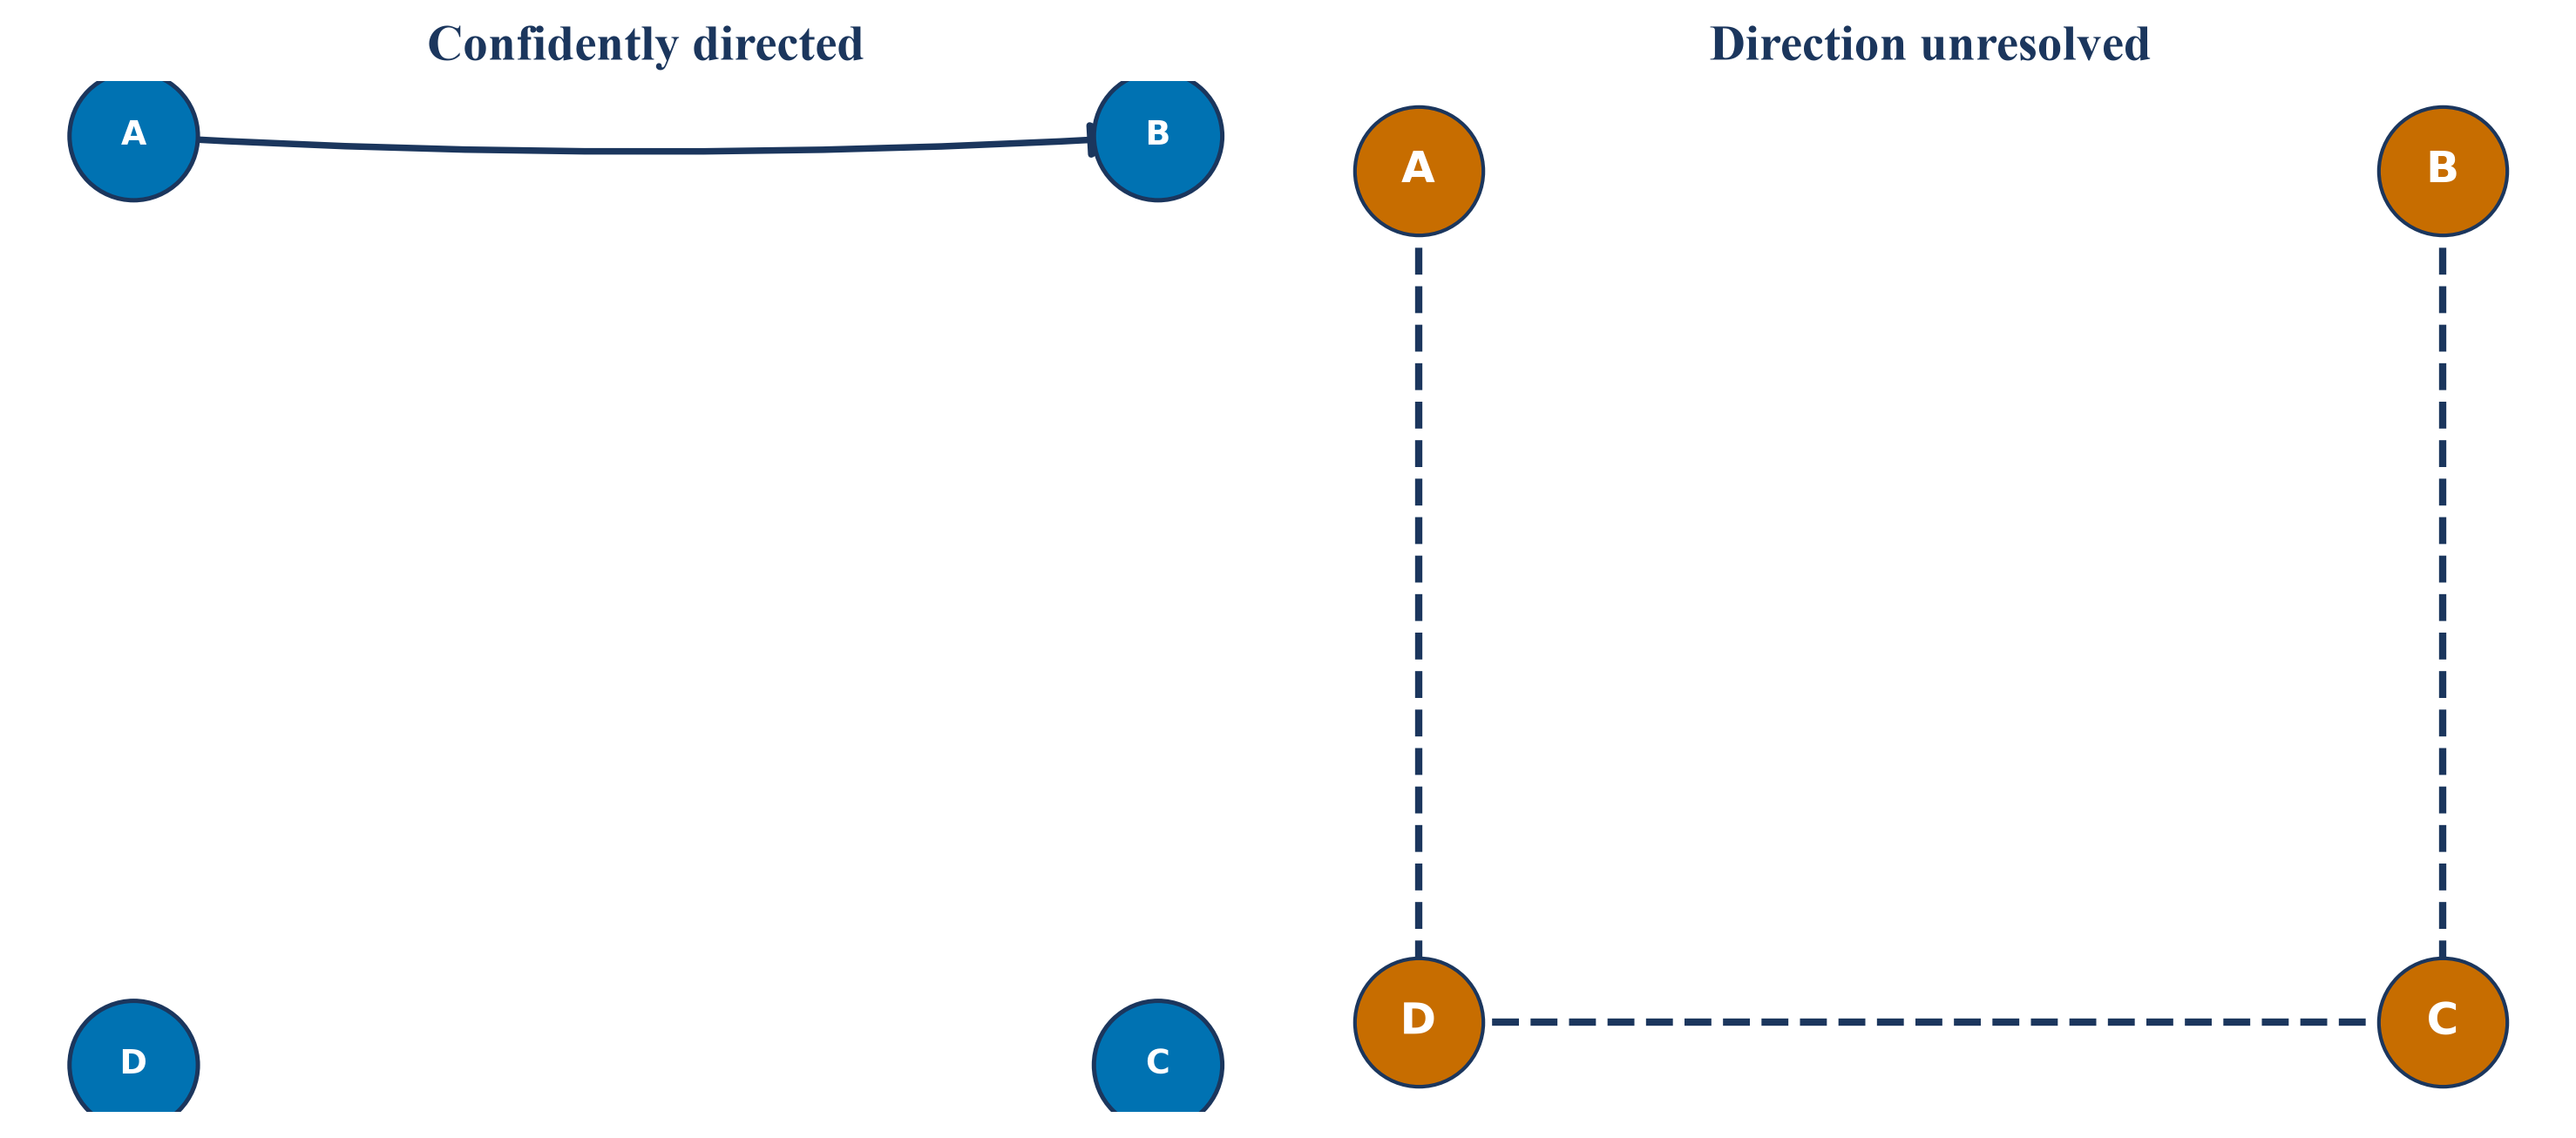

,Quantity,Value
0,Public observations,1760
1,Selected industries,8
2,Industry pairs,28
3,Conditioning candidates,6
4,Candidate arrow orientations,3
5,Rolling windows,1635
6,Directed translated edges,1
7,Unresolved translated edges,3
8,Figures,6
9,Generated tables,10


In [5]:
sys.path.insert(0, str(ROOT))
from causal_notebook_tools import _endpoint_matrix_to_digraph

endpoint_names = ["A", "B", "C", "D"]
endpoint_matrix = np.zeros((4, 4))
endpoint_matrix[0, 1], endpoint_matrix[1, 0] = -1, 1
endpoint_matrix[1, 2], endpoint_matrix[2, 1] = -1, -1
endpoint_matrix[0, 3], endpoint_matrix[3, 0] = 1, 1
endpoint_matrix[2, 3], endpoint_matrix[3, 2] = 2, 1
certain_graph, ambiguous_edges, bidirected_edges = _endpoint_matrix_to_digraph(endpoint_matrix, endpoint_names)
endpoint_translation = pd.DataFrame([{"From": source, "To": target, "Status": "Directed"} for source, target in certain_graph.edges])
ambiguous_edge_table = pd.DataFrame([{"First node": source, "Second node": target, "Status": kind} for source, target, kind in ambiguous_edges])
save_table(endpoint_translation, "endpoint_translation", "Confidently directed edges retained from the endpoint matrix.", "tab:chapter23-endpoint-translation")
save_table(ambiguous_edge_table, "ambiguous_edge_table", "Edges retained as unresolved rather than assigned a direction.", "tab:chapter23-ambiguous-edges")
display(endpoint_translation)
display(ambiguous_edge_table)

endpoint_positions = {"A": (0, 1), "B": (1, 1), "C": (1, 0), "D": (0, 0)}
ambiguous_graph = nx.Graph()
ambiguous_graph.add_nodes_from(endpoint_names)
ambiguous_graph.add_edges_from([(source, target) for source, target, kind in ambiguous_edges])
figure, axes = plt.subplots(1, 2, figsize=(10, 4.5))
draw_directed_graph(axes[0], certain_graph, endpoint_positions, "Confidently directed")
nx.draw_networkx_nodes(ambiguous_graph, endpoint_positions, ax=axes[1], node_color=palette["amber"], edgecolors=palette["text"], node_size=1250)
nx.draw_networkx_labels(ambiguous_graph, endpoint_positions, ax=axes[1], font_color=palette["background"], font_weight="bold")
nx.draw_networkx_edges(ambiguous_graph, endpoint_positions, ax=axes[1], edge_color=palette["text"], width=2.0, style="dashed")
axes[1].set_title("Direction unresolved")
axes[1].set_axis_off()
figure.tight_layout()
save_figure(figure, "endpoint_direction_uncertainty")

path_evidence_section_summary = pd.DataFrame({"Quantity": ["Public observations", "Selected industries", "Industry pairs", "Conditioning candidates", "Candidate arrow orientations", "Rolling windows", "Directed translated edges", "Unresolved translated edges", "Figures", "Generated tables"], "Value": [len(public_sample), len(public_sample.columns), len(public_association_summary), len(public_conditioning_screen), len(orientation_graphs), len(rolling_association), certain_graph.number_of_edges(), len(ambiguous_edges), 6, 10]})
save_table(path_evidence_section_summary, "path_evidence_section_summary", "Section 23.3 numerical summary.", "tab:chapter23-path-evidence-summary")
display(path_evidence_section_summary)

## Tests

In [6]:
assert data_hash == EXPECTED_DATA_HASH
assert public_sample.shape == (1760, 8)
assert np.allclose(public_correlation.to_numpy(), public_correlation.to_numpy().T)
assert np.allclose(np.diag(public_correlation), 1.0)
assert np.allclose(public_partial_correlation.to_numpy(), public_partial_correlation.to_numpy().T)
assert np.allclose(np.diag(public_partial_correlation), 1.0)
assert len(public_association_summary) == 28
assert len(public_conditioning_screen) == 6
assert set(orientation_role_uncertainty["Insurance role"]) == {"confounder", "mediator", "collider"}
assert orientation_role_uncertainty["Acyclic"].all()
assert orientation_covariance_reconstruction["Maximum covariance error"].max() < 1e-12
assert orientation_covariance_reconstruction["Smallest residual variance"].min() > 0.0
assert len(rolling_association) == len(public_sample) - rolling_window + 1
assert np.isfinite(rolling_association.to_numpy()).all()
assert list(certain_graph.edges()) == [("A", "B")]
assert {kind for _, _, kind in ambiguous_edges} == {"undirected", "bidirected", "circle"}
assert bidirected_edges == [("A", "D")]
assert len(path_evidence_section_summary) == 10
for stem in ["public_correlation_partial_matrices", "public_association_network", "public_conditioning_screen", "public_orientation_alternatives", "rolling_public_associations", "endpoint_direction_uncertainty"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["causal_public_data_provenance", "public_association_summary", "public_pairwise_partial_comparison", "public_conditioning_screen", "orientation_role_uncertainty", "orientation_covariance_reconstruction", "rolling_association_summary", "endpoint_translation", "ambiguous_edge_table", "path_evidence_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()